In [2]:
import tensorflow as tf
from tensorflow.keras import layers,models
from tensorflow.keras.applications import VGG16
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

In [4]:
(train_images,train_labels),(test_images,test_labels)=mnist.load_data()

In [5]:
train_images = train_images.reshape((60000, 28, 28, 1))
train_images = train_images.astype('float32') / 255
test_images = test_images.reshape((10000, 28, 28, 1))
test_images = test_images.astype('float32') / 255

In [6]:
train_images_resized = tf.image.resize(train_images, [32, 32])
test_images_resized = tf.image.resize(test_images, [32, 32])

In [7]:
train_images_rgb = tf.image.grayscale_to_rgb(train_images_resized)
test_images_rgb = tf.image.grayscale_to_rgb(test_images_resized)

In [8]:
train_label = to_categorical(train_labels)
test_label = to_categorical(test_labels)

In [9]:
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(32, 32, 3))

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [10]:
base_model.trainable = False

In [11]:
model = models.Sequential([
    base_model,
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

In [12]:
model.compile(optimizer = 'adam',loss='categorical_crossentropy',metrics=['accuracy'])

In [13]:
history = model.fit(train_images_rgb,train_label,epochs=5,batch_size=64,validation_split=0.2)

Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 21s 16ms/step - accuracy: 0.5734 - loss: 1.3129 - val_accuracy: 0.9109 - val_loss: 0.3426
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.8577 - loss: 0.4774 - val_accuracy: 0.9341 - val_loss: 0.2178
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.8933 - loss: 0.3571 - val_accuracy: 0.9435 - val_loss: 0.1819
Epoch 4/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.9085 - loss: 0.3032 - val_accuracy: 0.9481 - val_loss: 0.1621
Epoch 5/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.9173 - loss: 0.2776 - val_accuracy: 0.9525 - val_loss: 0.1493


In [15]:
test_loss = model.evaluate(test_images_rgb,test_label)
print(f'Test accuracy: {test_loss[1]}')

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9530 - loss: 0.1506
Test accuracy: 0.9569000005722046


In [19]:
Pred_test = model.predict(test_images_rgb)

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step


In [20]:
from sklearn.metrics import confusion_matrix

In [21]:
Predicted_labels = Pred_test.argmax(axis=1)

In [22]:
cm = confusion_matrix(test_labels,Predicted_labels)

Text(158.22222222222223, 0.5, 'Actual digits')

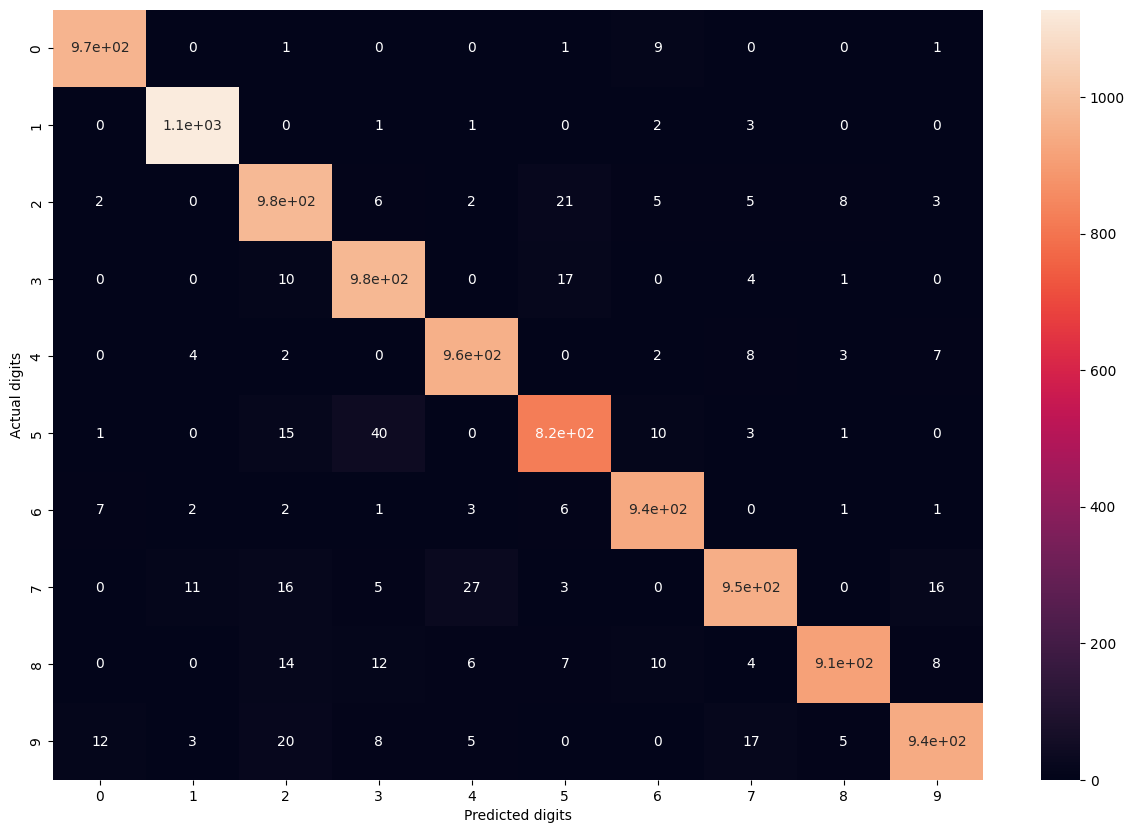

In [23]:
import seaborn as sn
import matplotlib.pyplot as plt
import seaborn as sn
plt.figure(figsize = (15,10))
sn.heatmap(cm,annot=True)
plt.xlabel('Predicted digits')
plt.ylabel('Actual digits')